Questo notebook contiene le sessioni di training dell'agente DDQN con funzione trainV2 in ambienti con p_err tipo X (bitflip) crescente. Rispettivamente:
- p_err 0.001 | run 13/10 230503 | best_avg_500_train : 10858
- p_err 0.003 | run 14/10 034106 | best_avg_500_train : 1654
- p_err 0.005 | run 14/10 081237 | best_avg_500_train : 557
- p_err 0.007 | run 14/10 234730 | best_avg_500_train : 277
- p_err 0.009 | run 15/10 044635 | best_avg_500_train : 138


Tutte le sessioni di training sono state svolte con una politica di eps-annealing lineare, con eps 1 --> 0.02 in 75k steps

Per ogni sessione sono presenti addestramento, una prima valutazione grafica di parametri e metriche di addestramento e il test effettuato sulla politica ottenuta.

In [1]:
# import delle librerie 
import numpy as np
import matplotlib.pyplot as plt
import torch

from Function_Library import *
from Environments import *
from Agent_Torch import *

import copy
import os
import time

In [ ]:
# # ripristino prima del codice successivo --> utile per sessioni training avviate consecutive in automatico
# del agent
# del policy_net
# del target_net
# del memory
# if torch.cuda.is_available():
#     torch.cuda.empty_cache()
# gc.collect()
# print("Pulizia della memoria effettuata. Le variabili principali sono state rimosse.")

## p_err = 0.001

In [2]:
fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.001,
                    "p_meas": 0.001,
                    "success_threshold": 10000,      
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,        
                    "exploration_fraction": 75000,  
                    "max_eps": 1.0,
                    "target_network_update_freq":5000, 
                    "gamma": 0.99,
                    "final_eps": 0.02}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali --> nuovo dueling
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# ottimizzatore
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])
policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device)

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [6]:
# V2 
timeS = time.time()
trainV2(agent, env, policy, policy_net, memory, all_configs, device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento su 1000000 passi. Log in: runs\DDQN_d5_p0.001_20251013-230503
*** Nuovo Best Model salvato! Avg Lifetime: 27.50 ***
*** Nuovo Best Model salvato! Avg Lifetime: 36.25 ***
*** Nuovo Best Model salvato! Avg Lifetime: 37.00 ***
*** Nuovo Best Model salvato! Avg Lifetime: 37.50 ***
*** Nuovo Best Model salvato! Avg Lifetime: 37.69 ***
*** Nuovo Best Model salvato! Avg Lifetime: 39.72 ***
*** Nuovo Best Model salvato! Avg Lifetime: 42.89 ***
*** Nuovo Best Model salvato! Avg Lifetime: 43.18 ***
*** Nuovo Best Model salvato! Avg Lifetime: 44.38 ***
*** Nuovo Best Model salvato! Avg Lifetime: 44.80 ***
*** Nuovo Best Model salvato! Avg Lifetime: 45.38 ***
*** Nuovo Best Model salvato! Avg Lifetime: 47.41 ***

--------------------------------
Episode: 100
Step: 1022/1000000
Episode Step : 2
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.78
Best Avg Reward: 1.26
Episode Lifetime : 20
Avg Lifetime (Last 500 Ep): 42.25
Best Avg Lifetime : 47.41
Success threshold : 10000
Patien

In [7]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 36 min


### valutazione log train

In [5]:
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.001_20251013-230503\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con trainV2 : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_d5_p0.001_20251013-230503\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 4626
numero step totali : 998906
best avg lifetime (rolling lenght 500) : 10858.33
----------------------------------------------------------


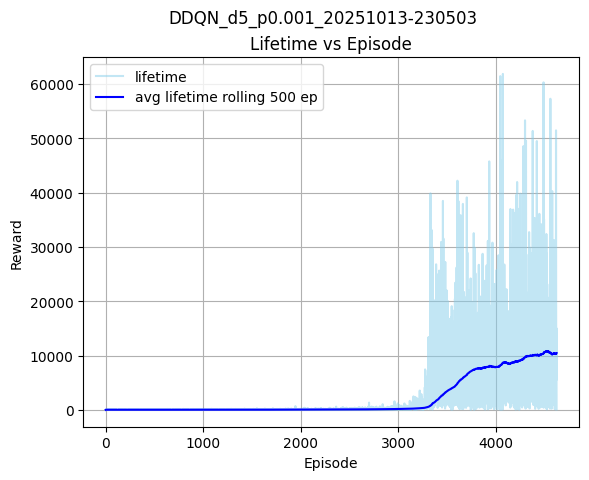

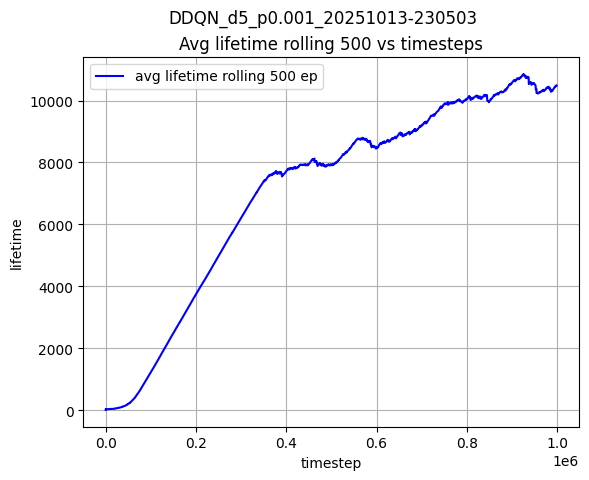

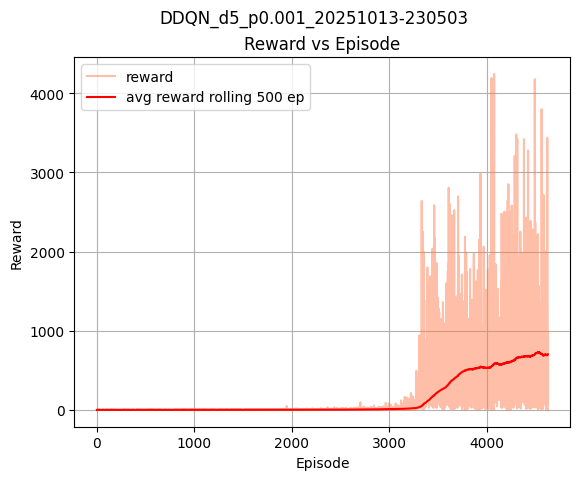

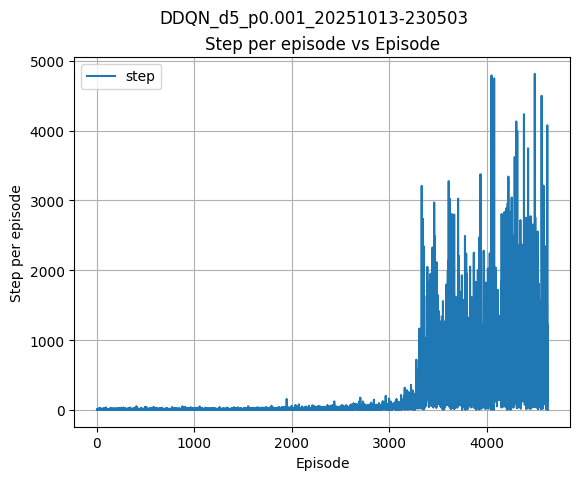

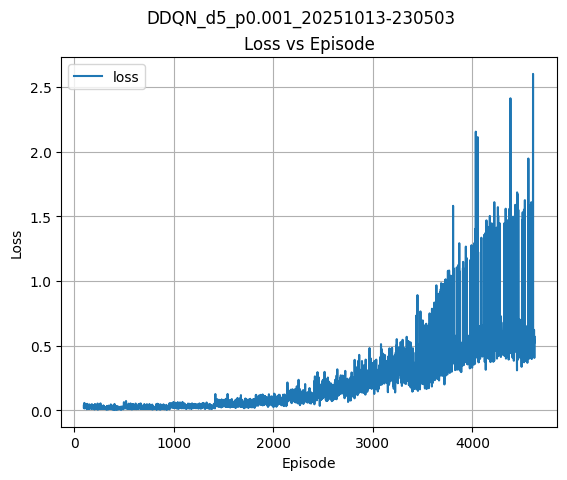

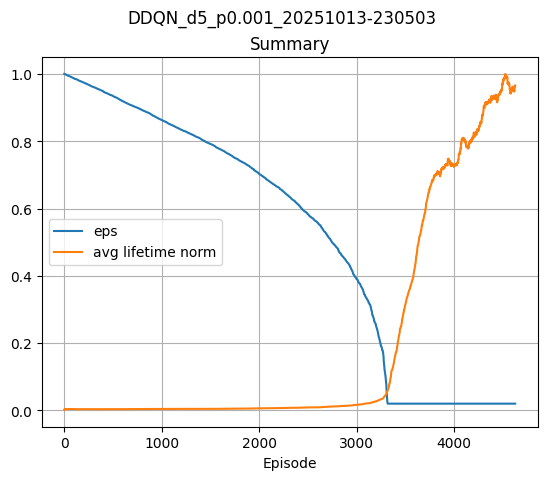

In [6]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

### test della policy ottenuta

In [ ]:
BEST_MODEL_PATH = r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

# test
N_episode = 1000
# test_avg_reward, test_std_reward, test_rewards, test_avg_lifetime, test_std_lifetime, test_lifetimes = test_agent_performance(env, policy_net, policy, N_episode, device)
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 1000) ---
tested episode : 10, steps : 1199, reward : 1135.0, lifetime : 17085
tested episode : 20, steps : 1350, reward : 1253.0, lifetime : 20350
tested episode : 30, steps : 1472, reward : 1383.0, lifetime : 19985
tested episode : 40, steps : 3626, reward : 3437.0, lifetime : 53945
tested episode : 50, steps : 144, reward : 132.0, lifetime : 2145
tested episode : 60, steps : 1465, reward : 1363.0, lifetime : 21050
tested episode : 70, steps : 1932, reward : 1814.0, lifetime : 26660
tested episode : 80, steps : 444, reward : 405.0, lifetime : 6270
tested episode : 90, steps : 69, reward : 65.0, lifetime : 1320
tested episode : 100, steps : 880, reward : 822.0, lifetime : 12085
tested episode : 110, steps : 1043, reward : 965.0, lifetime : 14980
tested episode : 120, steps : 986, reward : 945.0, lifetime : 13730
tested episode : 130, steps : 538, reward : 507.0, lifetime : 7675
tested episode : 140, steps : 325, reward : 304.0, lifetime : 4950

In [12]:
test_path = r'test_runs\test_policy_DDQN_d5_p0.001_20251013-230503.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_d5_p0.001_20251013-230503.json estratto con successo:


In [15]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 1000 ep, 45 min

16723355


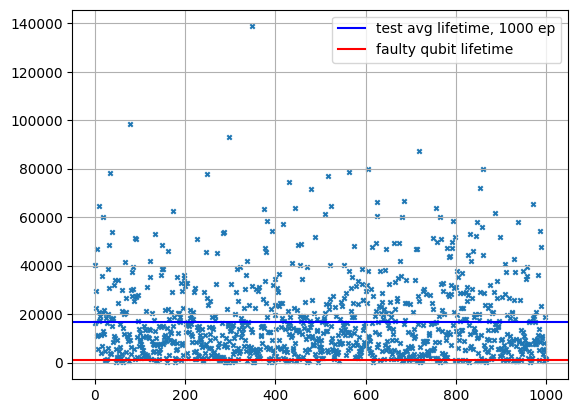

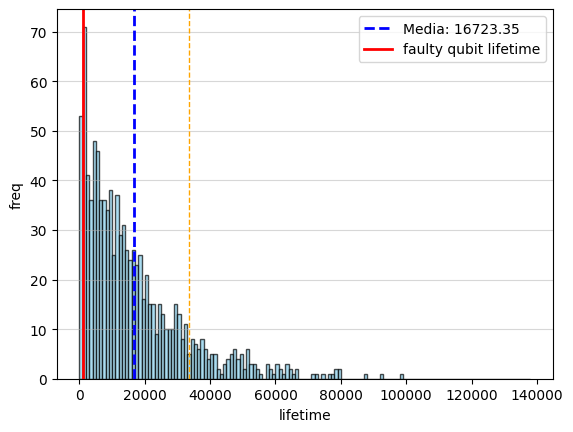

In [14]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p_err = 0.003

In [11]:

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            
                    "p_meas": 0.003,            
                    "success_threshold": 1100,       # necessaria per early stopping intelligente. impostata come almeno la vita media di un faulty qubit (1/p_err)
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,        
                    "exploration_fraction": 75000,  
                    "max_eps": 1.0,
                    "target_network_update_freq":5000, 
                    "gamma": 0.99,
                    "final_eps": 0.02}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [13]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali --> nuovo dueling
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# Inizializza l'Optimizer DOPO aver caricato i pesi
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# V2
timeS = time.time()
trainV2(agent, env, policy, policy_net, memory, all_configs, device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento su 1000000 passi. Log in: runs\DDQN_d5_p0.003_20251014-034106
*** Nuovo Best Model salvato! Avg Lifetime: 17.50 ***
*** Nuovo Best Model salvato! Avg Lifetime: 18.33 ***
*** Nuovo Best Model salvato! Avg Lifetime: 19.52 ***
*** Nuovo Best Model salvato! Avg Lifetime: 19.83 ***
*** Nuovo Best Model salvato! Avg Lifetime: 20.00 ***

--------------------------------
Episode: 100
Step: 843/1000000
Episode Step : 1
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.49
Best Avg Reward: 1.00
Episode Lifetime : 15
Avg Lifetime (Last 500 Ep): 19.25
Best Avg Lifetime : 20.00
Success threshold : 1100
Patience Counter: 0/1000
Metrics: Loss: N/A, Epsilon: 0.9890
Total Training Time: 3.11s
--------------------------------
                                  

--------------------------------
Episode: 200
Step: 1703/1000000
Episode Step : 10
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.52
Best Avg Reward: 1.00
Episode Lifetime : 15
Avg Lifetime (Last 500 Ep): 19.12
Best Avg Lifetime 

In [19]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 31 min


### valutazione log train

In [14]:
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.003_20251014-034106\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con trainV2 : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_d5_p0.003_20251014-034106\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 8208
numero step totali : 999701
best avg lifetime (rolling lenght 500) : 1654.43
----------------------------------------------------------


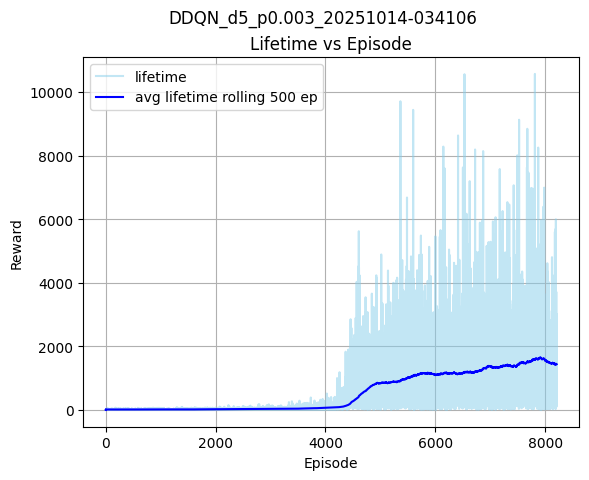

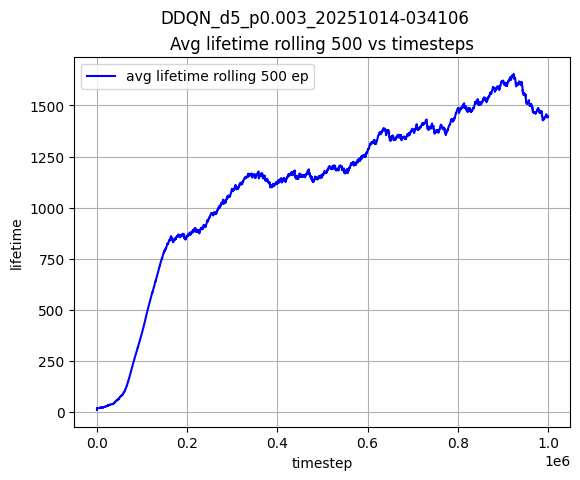

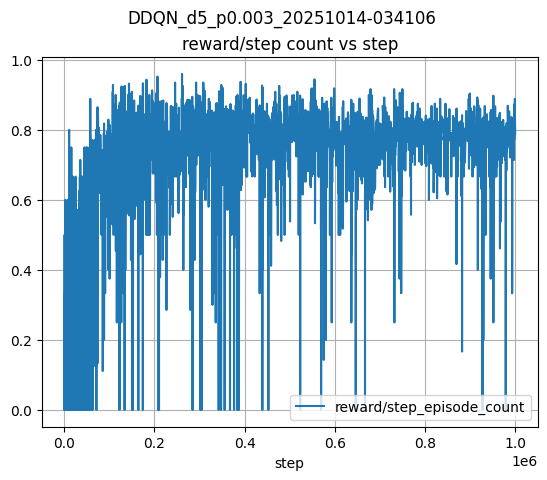

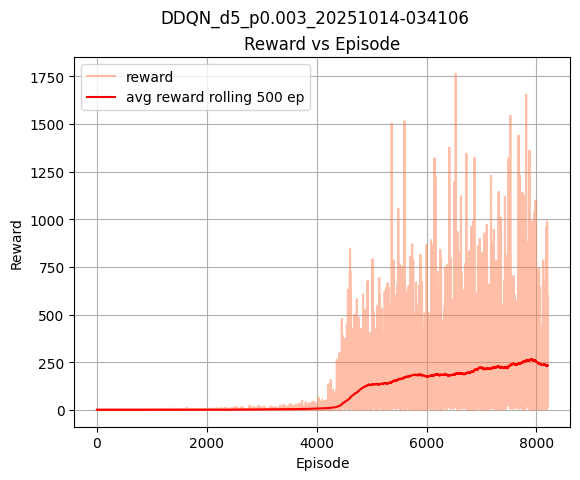

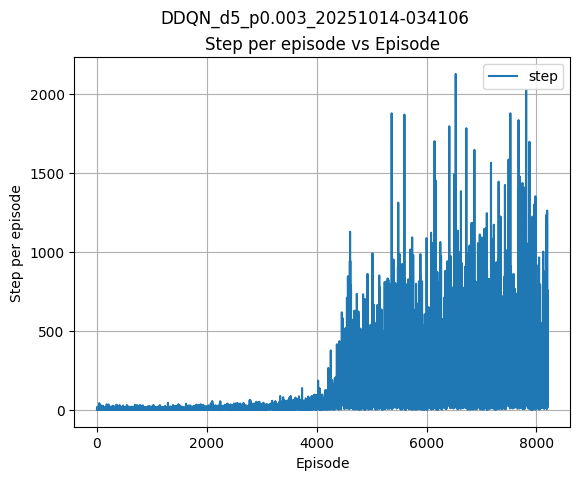

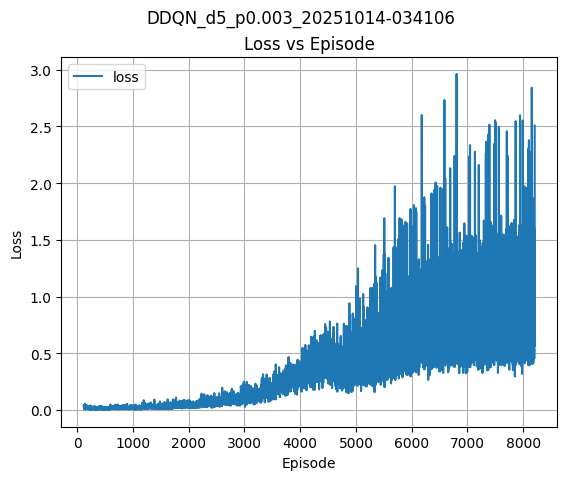

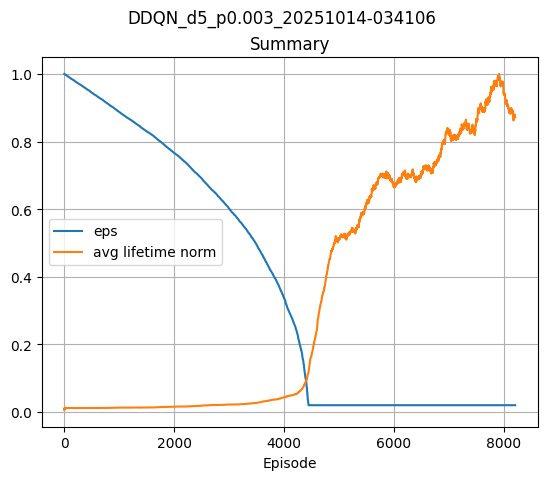

In [24]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# rew/step vs step
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, reward/episode_step_count, label='reward/step_episode_count')
ax.set_title('reward/step count vs step')
ax.set_xlabel('step')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()


### test della policy ottenuta

In [15]:
BEST_MODEL_PATH = r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

# test
N_episode = 1500
# test_avg_reward, test_std_reward, test_rewards, test_avg_lifetime, test_std_lifetime, test_lifetimes = test_agent_performance(env, policy_net, policy, N_episode, device)
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)




--- Inizio Test Deterministico (Episodi: 1500) ---
tested episode : 10, steps : 978, reward : 860.0, lifetime : 5240
tested episode : 20, steps : 304, reward : 275.0, lifetime : 1745
tested episode : 30, steps : 220, reward : 188.0, lifetime : 1260
tested episode : 40, steps : 230, reward : 204.0, lifetime : 1165
tested episode : 50, steps : 224, reward : 200.0, lifetime : 1235
tested episode : 60, steps : 364, reward : 316.0, lifetime : 2010
tested episode : 70, steps : 164, reward : 143.0, lifetime : 975
tested episode : 80, steps : 314, reward : 265.0, lifetime : 1550
tested episode : 90, steps : 486, reward : 436.0, lifetime : 2730
tested episode : 100, steps : 58, reward : 54.0, lifetime : 280
tested episode : 110, steps : 66, reward : 63.0, lifetime : 365
tested episode : 120, steps : 78, reward : 63.0, lifetime : 345
tested episode : 130, steps : 235, reward : 212.0, lifetime : 1185
tested episode : 140, steps : 305, reward : 273.0, lifetime : 1585
tested episode : 150, steps :

In [16]:
test_path = r'test_runs\test_policy_DDQN_d5_p0.003_20251014-034106.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_d5_p0.003_20251014-034106.json estratto con successo:


In [18]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 1500 ep, 14 min

2691805


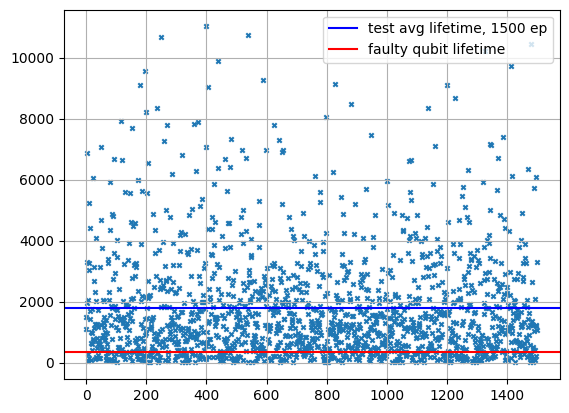

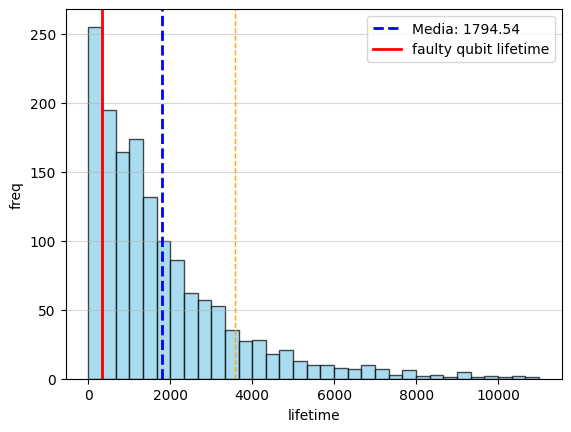

In [19]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p_err = 0.005

In [2]:

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.005,            # mod: 0.005
                    "p_meas": 0.005,            # mod: 0.005
                    "success_threshold": 440,       # necessaria per early stopping intelligente. impostata come almeno la vita media di un faulty qubit (1/p_err)
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,        
                    "exploration_fraction": 75000,  
                    "max_eps": 1.0,
                    "target_network_update_freq":5000, 
                    "gamma": 0.99,
                    "final_eps": 0.02}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali --> nuovo dueling
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# Inizializza l'Optimizer DOPO aver caricato i pesi
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [30]:
# V2
timeS = time.time()
trainV2(agent, env, policy, policy_net, memory, all_configs, device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento su 1000000 passi. Log in: runs\DDQN_d5_p0.005_20251014-081237

--------------------------------
Episode: 100
Step: 705/1000000
Episode Step : 13
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.46
Best Avg Reward: 1.00
Episode Lifetime : 30
Avg Lifetime (Last 500 Ep): 15.40
Best Avg Lifetime : 25.00
Success threshold : 440
Patience Counter: 0/1000
Metrics: Loss: N/A, Epsilon: 0.9908
Total Training Time: 4.42s
--------------------------------
                                  

--------------------------------
Episode: 200
Step: 1513/1000000
Episode Step : 14
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.41
Best Avg Reward: 1.00
Episode Lifetime : 25
Avg Lifetime (Last 500 Ep): 15.50
Best Avg Lifetime : 25.00
Success threshold : 440
Patience Counter: 0/1000
Metrics: Loss: 0.0104, Epsilon: 0.9802
Total Training Time: 17.03s
--------------------------------
                                  

--------------------------------
Episode: 300
Step: 2246/1000000
Episode Step

In [31]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

3 ore e 54 min


### valutazione log train

In [5]:
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.005_20251014-081237\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con trainV2 : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_d5_p0.005_20251014-081237\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 11003
numero step totali : 749438
best avg lifetime (rolling lenght 500) : 557.16
----------------------------------------------------------


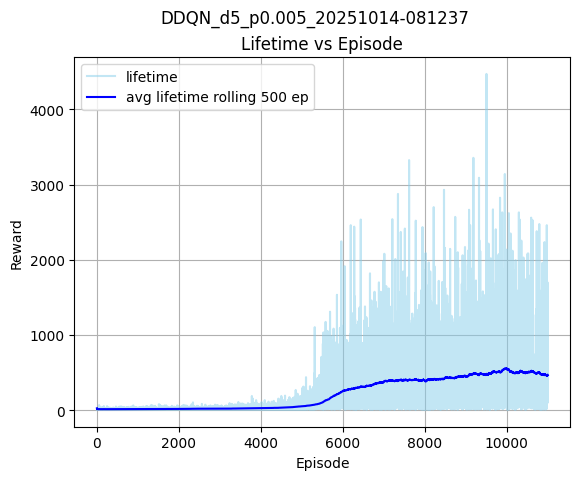

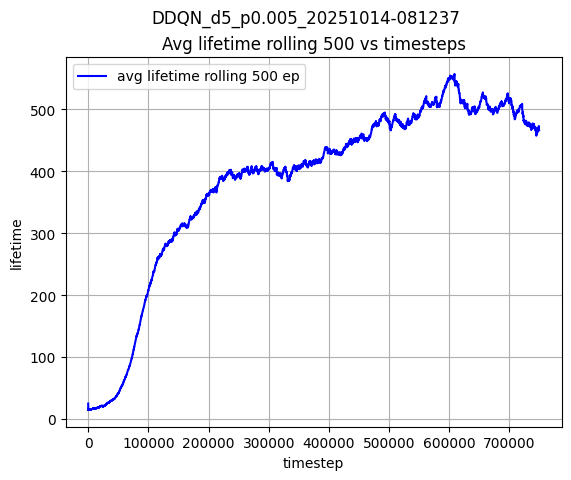

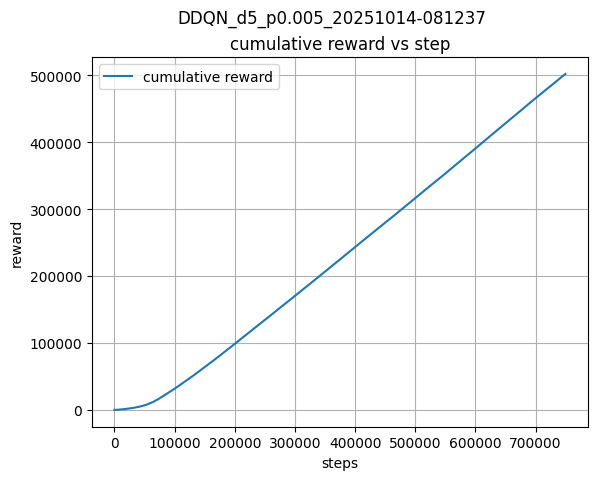

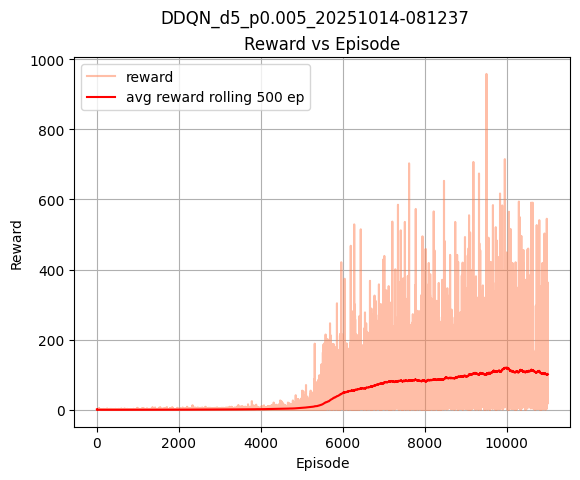

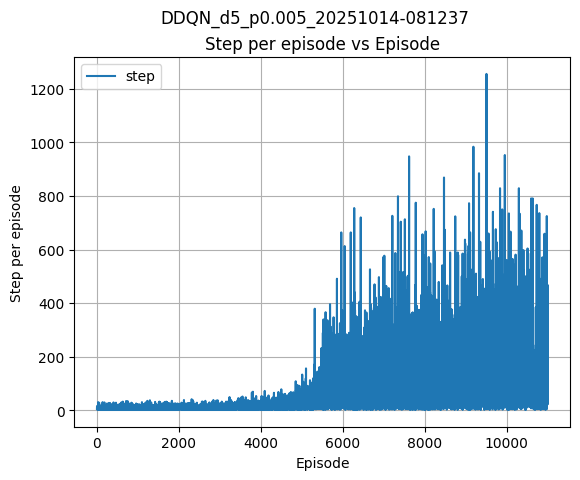

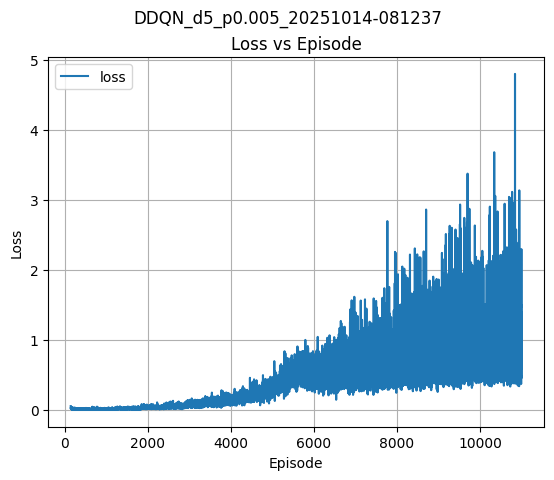

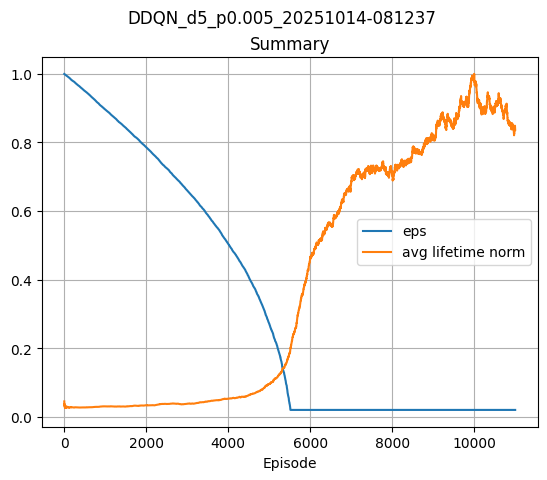

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
# ax.set_xlim(right=130000)
ax.legend()
ax.grid()
plt.show()

# add 
# non troppo utile ai fini della dimostrazione 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

### test della policy ottenuta

In [6]:
BEST_MODEL_PATH = r'runs\DDQN_d5_p0.005_20251014-081237\checkpoints\best_policy_net.pth'
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

# test : inizializzare nuovamente env e agente
N_episode = 3500
# test_avg_reward, test_std_reward, test_rewards, test_avg_lifetime, test_std_lifetime, test_lifetimes = test_agent_performance(env, policy_net, policy, N_episode, device)
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 3500) ---
tested episode : 10, steps : 8, reward : 4.0, lifetime : 40
tested episode : 20, steps : 423, reward : 323.0, lifetime : 1535
tested episode : 30, steps : 16, reward : 9.0, lifetime : 85
tested episode : 40, steps : 88, reward : 71.0, lifetime : 315
tested episode : 50, steps : 51, reward : 40.0, lifetime : 170
tested episode : 60, steps : 258, reward : 217.0, lifetime : 995
tested episode : 70, steps : 15, reward : 9.0, lifetime : 40
tested episode : 80, steps : 473, reward : 395.0, lifetime : 1770
tested episode : 90, steps : 99, reward : 81.0, lifetime : 365
tested episode : 100, steps : 526, reward : 437.0, lifetime : 1935
tested episode : 110, steps : 227, reward : 187.0, lifetime : 840
tested episode : 120, steps : 55, reward : 43.0, lifetime : 225
tested episode : 130, steps : 44, reward : 28.0, lifetime : 145
tested episode : 140, steps : 172, reward : 136.0, lifetime : 635
tested episode : 150, steps : 262, reward : 223.0, li

In [7]:
test_path = r'test_runs\test_policy_DDQN_d5_p0.005_20251014-081237.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_d5_p0.005_20251014-081237.json estratto con successo:


In [8]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 3500 ep, 21  min

2284895


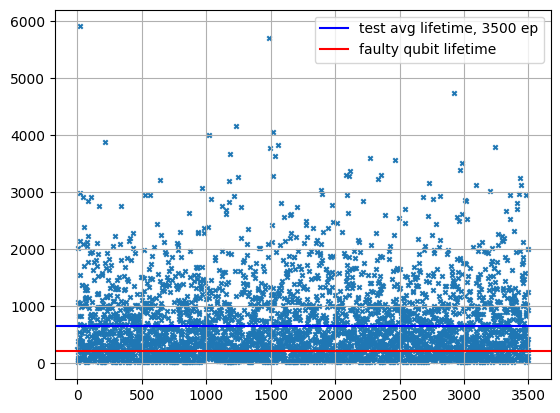

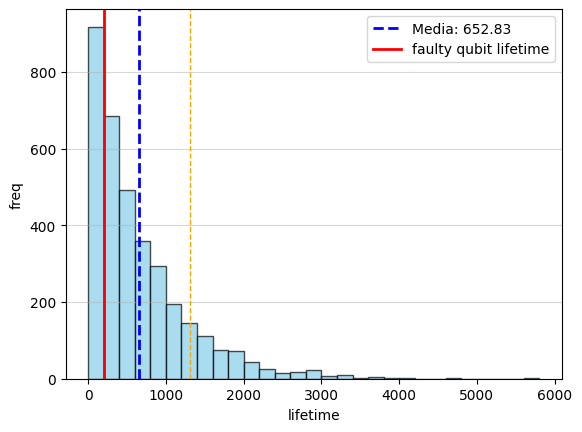

In [9]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()


## p_err = 0.007

In [2]:

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.007,            
                    "p_meas": 0.007,            
                    "success_threshold": 230,       # necessaria per early stopping intelligente. impostata come almeno la vita media di un faulty qubit (1/p_err)
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,        
                    "exploration_fraction": 75000,  
                    "max_eps": 1.0,
                    "target_network_update_freq":5000, 
                    "gamma": 0.99,
                    "final_eps": 0.02}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali --> nuovo dueling
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# Inizializza l'Optimizer DOPO aver caricato i pesi
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [5]:
# V2
timeS = time.time()
trainV2(agent, env, policy, policy_net, memory, all_configs, device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento su 1000000 passi. Log in: runs\DDQN_d5_p0.007_20251014-234730
*** Nuovo Best Model salvato! Avg Lifetime: 16.25 ***
*** Nuovo Best Model salvato! Avg Lifetime: 17.00 ***

--------------------------------
Episode: 100
Step: 652/1000000
Episode Step : 9
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.26
Best Avg Reward: 0.57
Episode Lifetime : 15
Avg Lifetime (Last 500 Ep): 11.70
Best Avg Lifetime : 17.00
Success threshold : 230
Patience Counter: 0/1000
Metrics: Loss: N/A, Epsilon: 0.9915
Total Training Time: 3.09s
--------------------------------
                                  

--------------------------------
Episode: 200
Step: 1391/1000000
Episode Step : 6
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.31
Best Avg Reward: 0.57
Episode Lifetime : 5
Avg Lifetime (Last 500 Ep): 12.25
Best Avg Lifetime : 17.00
Success threshold : 230
Patience Counter: 0/1000
Metrics: Loss: 0.0171, Epsilon: 0.9818
Total Training Time: 11.33s
--------------------------------
        

In [6]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 59 min


### valutazione log train

In [5]:
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.007_20251014-234730\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con trainV2 : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_d5_p0.007_20251014-234730\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 15182
numero step totali : 708422
best avg lifetime (rolling lenght 500) : 277.01
----------------------------------------------------------


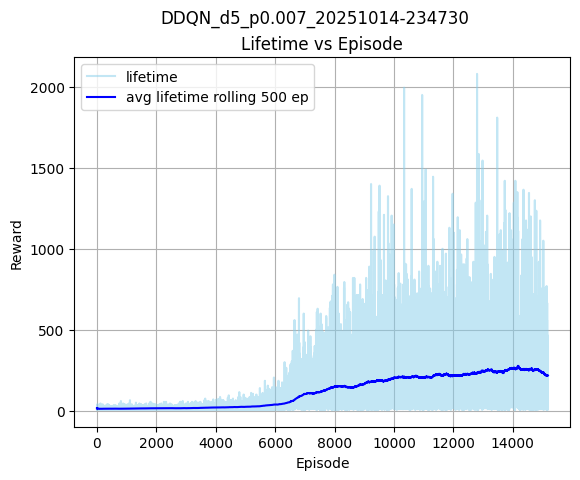

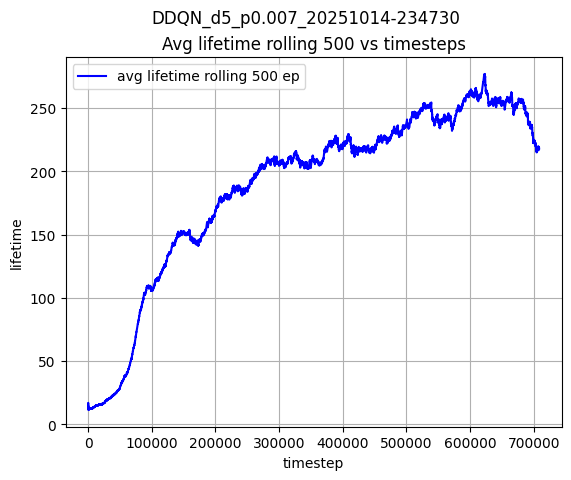

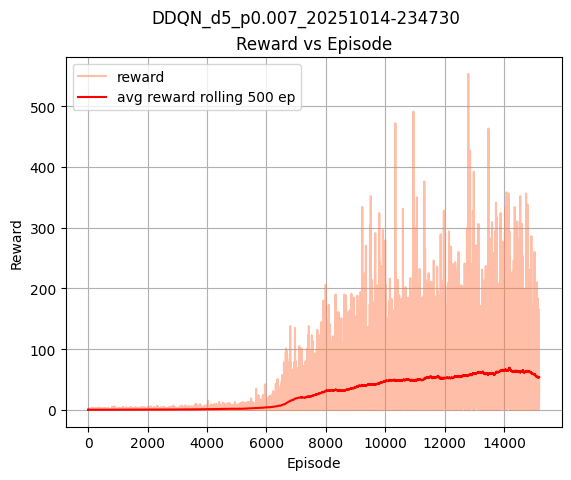

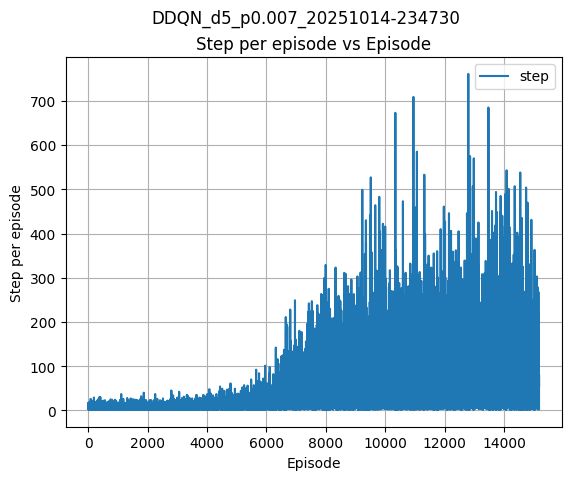

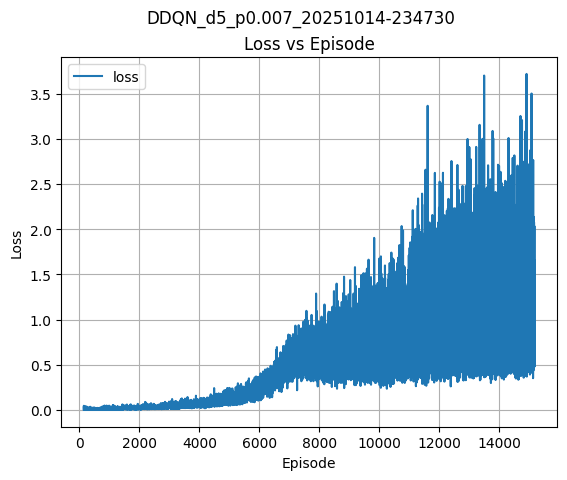

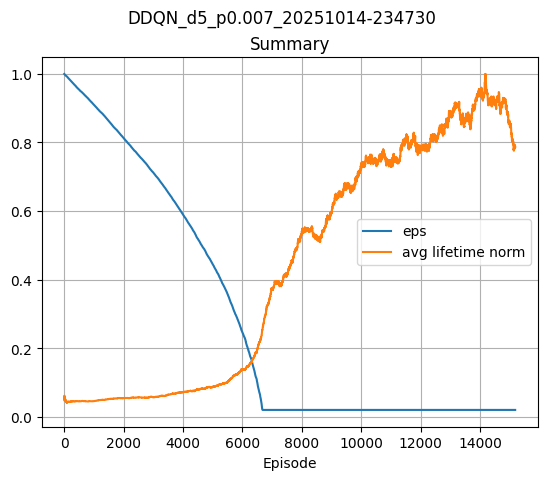

In [34]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

### test della policy ottenuta

In [6]:
BEST_MODEL_PATH = r'runs\DDQN_d5_p0.007_20251014-234730\checkpoints\best_policy_net.pth'
# Caricamento e Modalità Valutazione
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

# test : ricorda di eseguire prima le celle di inizializzazione env, agente e risultati (nome run)
N_episode = 6500
# test_avg_reward, test_std_reward, test_rewards, test_avg_lifetime, test_std_lifetime, test_lifetimes = test_agent_performance(env, policy_net, policy, N_episode, device)
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 6500) ---
tested episode : 10, steps : 39, reward : 28.0, lifetime : 105
tested episode : 20, steps : 69, reward : 47.0, lifetime : 190
tested episode : 30, steps : 70, reward : 61.0, lifetime : 220
tested episode : 40, steps : 41, reward : 31.0, lifetime : 130
tested episode : 50, steps : 21, reward : 15.0, lifetime : 85
tested episode : 60, steps : 621, reward : 482.0, lifetime : 1835
tested episode : 70, steps : 209, reward : 164.0, lifetime : 645
tested episode : 80, steps : 212, reward : 151.0, lifetime : 565
tested episode : 90, steps : 132, reward : 108.0, lifetime : 395
tested episode : 100, steps : 29, reward : 20.0, lifetime : 80
tested episode : 110, steps : 4, reward : 3.0, lifetime : 15
tested episode : 120, steps : 68, reward : 51.0, lifetime : 185
tested episode : 130, steps : 110, reward : 74.0, lifetime : 300
tested episode : 140, steps : 191, reward : 151.0, lifetime : 585
tested episode : 150, steps : 105, reward : 82.0, life

In [7]:
test_path = r'test_runs\test_policy_DDQN_d5_p0.007_20251014-234730.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_d5_p0.007_20251014-234730.json estratto con successo:


In [8]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 6500 ep, 29 min

2210585


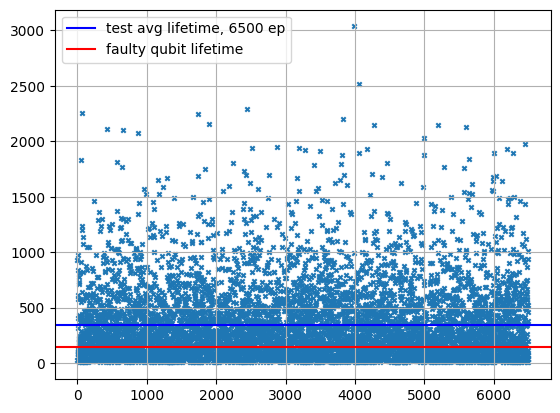

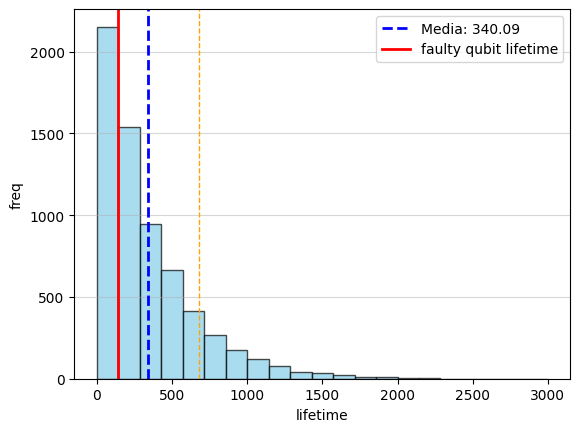

In [9]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()



## p_err = 0.009

In [2]:

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.009,            
                    "p_meas": 0.009,            
                    "success_threshold": 150,       # necessaria per early stopping intelligente. impostata come almeno la vita media di un faulty qubit (1/p_err)
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,        
                    "exploration_fraction": 75000,  
                    "max_eps": 1.0,
                    "target_network_update_freq":5000, 
                    "gamma": 0.99,
                    "final_eps": 0.02}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali --> nuovo dueling
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# Inizializza l'Optimizer DOPO aver caricato i pesi
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# V2 --> interrotto a 750k steps circa 
timeS = time.time()
trainV2(agent, env, policy, policy_net, memory, all_configs, device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento su 1000000 passi. Log in: runs\DDQN_d5_p0.009_20251015-044635
*** Nuovo Best Model salvato! Avg Lifetime: 11.25 ***
*** Nuovo Best Model salvato! Avg Lifetime: 12.00 ***
*** Nuovo Best Model salvato! Avg Lifetime: 12.14 ***
*** Nuovo Best Model salvato! Avg Lifetime: 12.50 ***
*** Nuovo Best Model salvato! Avg Lifetime: 13.89 ***

--------------------------------
Episode: 100
Step: 701/1000000
Episode Step : 20
Episode Reward : 0
Avg Reward (Last 500 Ep): 0.22
Best Avg Reward: 0.50
Episode Lifetime : 25
Avg Lifetime (Last 500 Ep): 12.50
Best Avg Lifetime : 13.89
Success threshold : 150
Patience Counter: 0/1000
Metrics: Loss: N/A, Epsilon: 0.9908
Total Training Time: 3.40s
--------------------------------
                                  

--------------------------------
Episode: 200
Step: 1369/1000000
Episode Step : 17
Episode Reward : 1.0
Avg Reward (Last 500 Ep): 0.21
Best Avg Reward: 0.50
Episode Lifetime : 25
Avg Lifetime (Last 500 Ep): 12.07
Best Avg Lifetim

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')
# nb allenamento interrotto 

6 ore e 35 min


### valutazione log train

In [5]:
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.009_20251015-044635\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con trainV2 : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_d5_p0.009_20251015-044635\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 22949
numero step totali : 757902
best avg lifetime (rolling lenght 500) : 138.69
----------------------------------------------------------


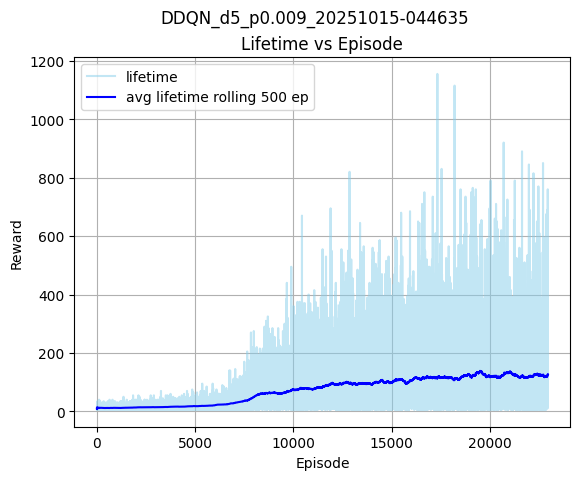

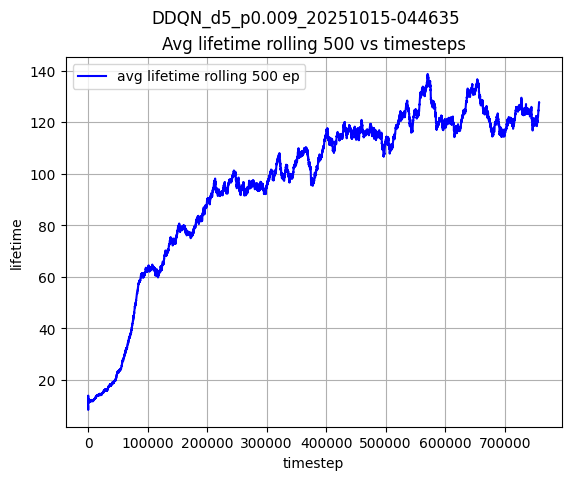

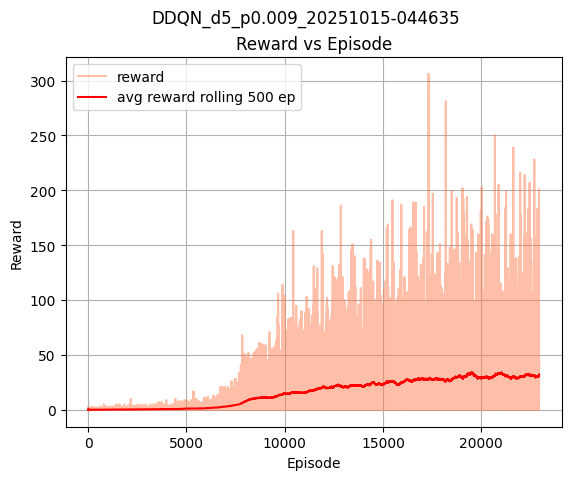

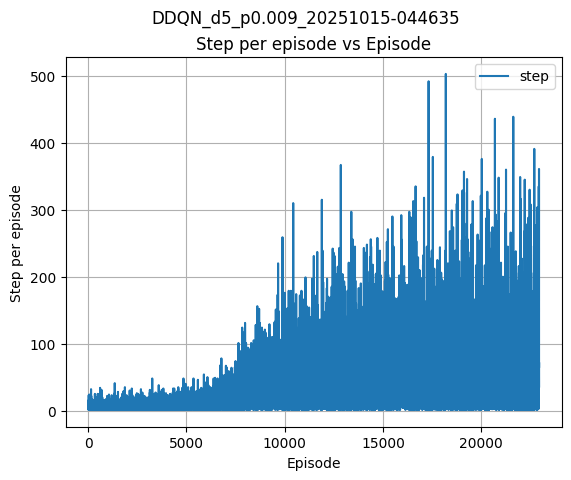

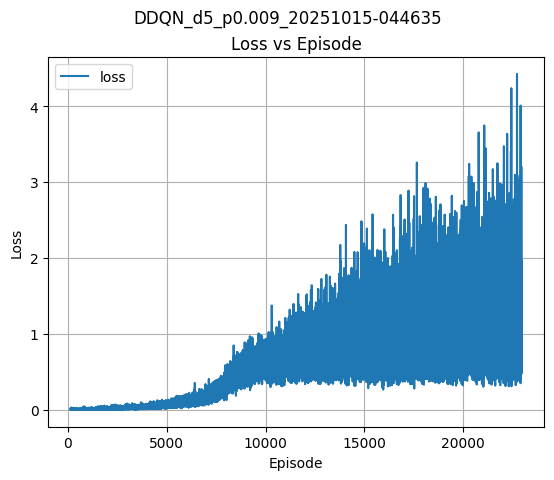

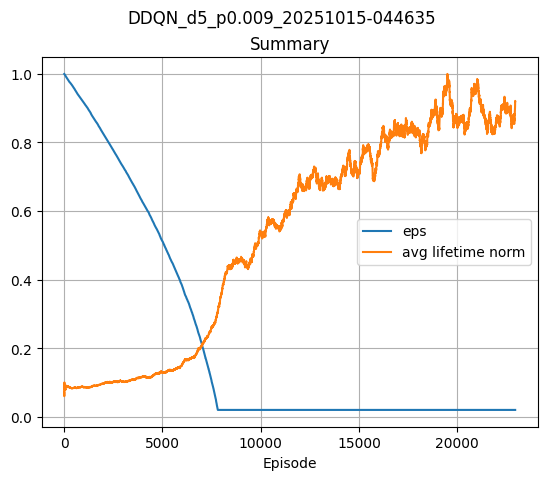

In [39]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

### test della policy ottenuta

In [6]:
BEST_MODEL_PATH = r'runs\DDQN_d5_p0.009_20251015-044635\checkpoints\best_policy_net.pth'
# Caricamento e Modalità Valutazione
policy_net.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
policy_net.eval() 

# test : ricorda di eseguire prima le celle di inizializzazione env, agente e risultati (nome run)
N_episode = 15500
# test_avg_reward, test_std_reward, test_rewards, test_avg_lifetime, test_std_lifetime, test_lifetimes = test_agent_performance(env, policy_net, policy, N_episode, device)
test_path = test_agent_performance(env, policy_net, policy, N_episode, device, log=True, run_name=run)



--- Inizio Test Deterministico (Episodi: 15500) ---
tested episode : 10, steps : 67, reward : 45.0, lifetime : 160
tested episode : 20, steps : 34, reward : 19.0, lifetime : 70
tested episode : 30, steps : 13, reward : 10.0, lifetime : 40
tested episode : 40, steps : 3, reward : 2.0, lifetime : 15
tested episode : 50, steps : 132, reward : 90.0, lifetime : 335
tested episode : 60, steps : 32, reward : 21.0, lifetime : 70
tested episode : 70, steps : 9, reward : 8.0, lifetime : 30
tested episode : 80, steps : 9, reward : 8.0, lifetime : 30
tested episode : 90, steps : 66, reward : 35.0, lifetime : 155
tested episode : 100, steps : 78, reward : 58.0, lifetime : 185
tested episode : 110, steps : 19, reward : 6.0, lifetime : 35
tested episode : 120, steps : 13, reward : 5.0, lifetime : 25
tested episode : 130, steps : 15, reward : 7.0, lifetime : 35
tested episode : 140, steps : 11, reward : 9.0, lifetime : 30
tested episode : 150, steps : 91, reward : 60.0, lifetime : 240
tested episode 

In [7]:
test_path = r'test_runs\test_policy_DDQN_d5_p0.009_20251015-044635.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.mean(test_lifetimes)

Contenuto di test_runs\test_policy_DDQN_d5_p0.009_20251015-044635.json estratto con successo:


In [8]:
# nb: il paper originale calcola la vita media su un test greedy eseguito su un numero di episodi tale da garantire che
#     l'agente veda "almeno 1000000 di faulty syndrome" 
# la lifetime è calcolata come il  numero di singoli strati di ft syndrome creati in un qubit logico
# --> questo dato corrisponde alla somma di tutte le lifetime degli episodi di un test
print(np.sum(test_lifetimes))
# 15500 ep, 69 min

2523370


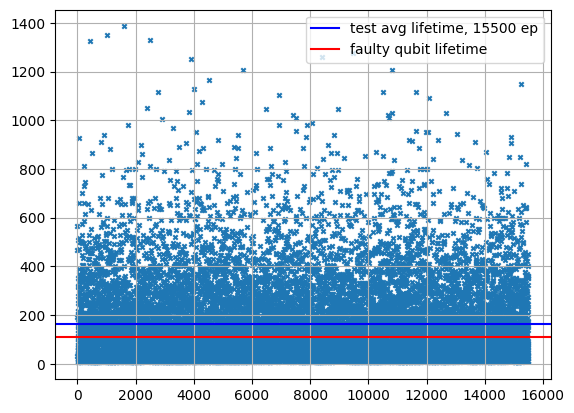

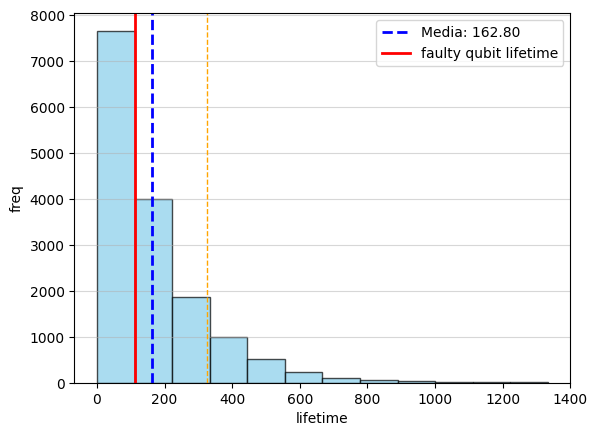

In [9]:
faulty_qubit_lifetime = 1/all_configs['p_phys']

fig, ax = plt.subplots()
ax.axhline(test_avg_lifetime, c='b', label=f'test avg lifetime, {N_episode} ep')
ax.scatter(range(N_episode), test_lifetimes, marker='x', s=10 )
ax.axhline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r')
ax.grid()
ax.legend()
plt.show()

bins = np.arange(0, np.max(test_lifetimes), faulty_qubit_lifetime)
# istogramma

plt.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.7, color='skyblue')
# Aggiungi linee di riferimento per la Media e la Deviazione Standard
plt.axvline(test_avg_lifetime, c='b', ls='dashed', linewidth=2, label=f'Media: {test_avg_lifetime:.2f}')
plt.axvline(test_avg_lifetime + test_std_lifetime, color='orange', linestyle='dashed', linewidth=1)
if test_avg_lifetime - test_std_lifetime > 0: plt.axvline(test_avg_lifetime - test_std_lifetime, color='orange', linestyle='dashed', linewidth=1, label=f'Media ± Std: {test_std_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, label='faulty qubit lifetime', c='r', lw=2)
# Etichette e Titolo
plt.xlabel('lifetime')
plt.ylabel('freq')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

